In [1]:
import csv
import io
import re
import time
import zipfile
from dataclasses import dataclass, field
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize, LinearConstraint, Bounds

import cvxpy as cp

from sympy import symbols, lambdify, sympify
from sympy.parsing.sympy_parser import parse_expr

from common_libs import check_vector, plot_convergence, show_iteration_table

## Nạp và tiền xử lý dữ liệu

### 1. Đọc và chuẩn hóa dữ liệu
- Sử dụng ba bộ dữ liệu lợi suất danh mục **FF10, FF48 và FF100**.
- Chuẩn hóa cột `Date` về kiểu thời gian, chuyển lợi suất sang kiểu số và sắp xếp theo tháng.
- Kiểm tra số lượng tài sản, dữ liệu thiếu, giá trị vô hạn, tháng trùng lặp và tháng bị thiếu.

### 2. Làm sạch dữ liệu
- Thiết lập `CLEAN=True`, `FILL="zero"`.
- Thay các mã dữ liệu thiếu `-99.99`, `-999` và giá trị `NaN` bằng `0`. (cái này có thể chọn ở cell code dưới - hiện tại bài đang chọn là fill bằng 0)
- Chuyển lợi suất từ phần trăm sang dạng thập phân bằng cách chia cho 100.

### 3. Xây dựng cửa sổ trượt (Rolling Window) (cho giai đoạn kiểm tra hiệu quả của mô hình với bài toán tối ưu danh mục đầu tư)
- **Huấn luyện (Train):** 60 tháng.
- **Kiểm thử (Test):** 12 tháng tiếp theo.
- **Giai đoạn kiểm thử:** 07/1976 – 06/2006.
- Dịch cửa sổ 12 tháng sau mỗi lần kiểm thử, tạo tối đa 30 cửa sổ cho mỗi bộ dữ liệu nếu dữ liệu đầy đủ.

### 4. Chuẩn bị đầu vào cho thuật toán
Tại mỗi cửa sổ cho bộ dữ liệu, ta có:

| Biến | Ý nghĩa |
|---|---|
| `R_train` | Ma trận lợi suất huấn luyện |
| `R_test` | Ma trận lợi suất kiểm thử |
| `mu` | Vectơ lợi suất trung bình trên tập Train |
| `Sigma` | Ma trận hiệp phương sai mẫu |
| `rho` | Lợi suất mục tiêu của danh mục phân bổ đều |
| `x_equal` | Vectơ trọng số phân bổ đều \(1/N\) |

**Kết quả:** Dữ liệu được tổ chức thành các danh sách `windows_ff10`, `windows_ff48`, `windows_ff100`. Mỗi phần tử chứa dữ liệu huấn luyện, kiểm thử và các tham số cần thiết để đưa vào thuật toán tối ưu danh mục đầu tư.

In [2]:
def read_french_csv(path, n_assets):
    """
    Trả về:
        DataFrame gồm Date (YYYYMM)
        và n_assets cột lợi suất (%).
    """
    path = Path(path)

    if path.suffix.lower() == ".zip":
        with zipfile.ZipFile(path) as z:
            names = [
                name for name in z.namelist()
                if name.lower().endswith(".csv")
            ]

            if len(names) != 1:
                raise ValueError(
                    f"ZIP phải chứa đúng 1 CSV: {names}"
                )

            raw_bytes = z.read(names[0])
    else:
        raw_bytes = path.read_bytes()

    try:
        text = raw_bytes.decode("utf-8-sig")
    except UnicodeDecodeError:
        text = raw_bytes.decode("latin-1")

    lines = text.splitlines()

    def is_month(s):
        return re.fullmatch(
            r"\s*\d{6}\s*", str(s)
        ) is not None

    for i in range(len(lines) - 1):
        header = lines[i].split(",")
        first_row = lines[i + 1].split(",")

        if not (
            len(header) == n_assets + 1
            and len(first_row) == n_assets + 1
            and is_month(first_row[0])
        ):
            continue

        rows = [lines[i]]
        j = i + 1

        while j < len(lines):
            fields = lines[j].split(",")

            if not (
                len(fields) == n_assets + 1
                and is_month(fields[0])
            ):
                break

            rows.append(lines[j])
            j += 1

        # Bỏ qua các khối không đủ 12 tháng
        if len(rows) < 13:
            continue

        df = pd.read_csv(
            io.StringIO("\n".join(rows)),
            skipinitialspace=True
        )

        return df

    raise ValueError(
        "Không tìm thấy bảng lợi suất tháng "
        f"gồm {n_assets} danh mục."
    )


def read_portfolio_file(path, n_assets):
    """
    Input:
        path: đường dẫn file
        n_assets: 10, 48 hoặc 100

    Output:
        DataFrame với lợi suất gốc (%).
    """
    path = Path(path)
    suffix = path.suffix.lower()

    if suffix in [".csv", ".zip"]:
        df = read_french_csv(path, n_assets)

    elif suffix in [".xlsx", ".xls"]:
        df = pd.read_excel(path)

    else:
        raise ValueError(
            f"Định dạng không hỗ trợ: {suffix}"
        )

    # Cột đầu tiên là thời gian
    df = df.rename(
        columns={df.columns[0]: "Date"}
    )

    if df.shape[1] != n_assets + 1:
        raise ValueError(
            f"Cần {n_assets} cột lợi suất, "
            f"nhưng file có {df.shape[1] - 1}."
        )

    return df


def parse_returns(df):
    """
    Chuẩn hóa:
      - Date thành datetime
      - Các cột lợi suất thành kiểu số
      - Sắp xếp tăng dần theo thời gian

    Không xử lý missing codes.
    Không chia cho 100.
    """
    data = df.copy()

    if pd.api.types.is_datetime64_any_dtype(data["Date"]):
        data["Date"] = pd.to_datetime(data["Date"])
    else:
        dates = (
            data["Date"]
            .astype("string")
            .str.strip()
            .str.replace(r"\.0$", "", regex=True)
        )

        data["Date"] = pd.to_datetime(
            dates,
            format="%Y%m",
            errors="raise"
        )

    asset_cols = data.columns.drop("Date")

    data[asset_cols] = data[asset_cols].apply(
        pd.to_numeric,
        errors="coerce"
    )

    data = (
        data.sort_values("Date")
        .reset_index(drop=True)
    )

    if data["Date"].duplicated().any():
        raise ValueError("Có tháng trùng lặp.")

    return data


def clean_returns(df, clean=True, fill="nan"):
    """
    Xử lý mã thiếu dữ liệu của Ken French.

    clean=False:
        Không thay đổi lợi suất.

    clean=True, fill="nan":
        -99.99, -999 -> NaN

    clean=True, fill="zero":
        -99.99, -999 -> 0
        Các NaN có sẵn cũng -> 0

    Output:
        DataFrame mới, không sửa df gốc.
        Lợi suất vẫn ở dạng %.
    """
    data = df.copy()

    if not clean:
        return data

    if fill not in ("nan", "zero"):
        raise ValueError(
            "fill phải là 'nan' hoặc 'zero'."
        )

    asset_cols = data.columns.drop("Date")

    # Bước 1: nhận diện mã thiếu
    data[asset_cols] = data[asset_cols].replace(
        [-99.99, -999.0],
        np.nan
    )

    # Bước 2: chọn cách xử lý
    if fill == "zero":
        data[asset_cols] = (
            data[asset_cols].fillna(0.0)
        )

    return data


def convert_to_decimal(df):
    """
    Chuyển lợi suất từ % sang thập phân.

    2.5% -> 0.025
    """
    data = df.copy()
    asset_cols = data.columns.drop("Date")

    data[asset_cols] = data[asset_cols] / 100.0

    return data


def inspect_returns(df, name="Dataset", decimal=False):
    """
    Kiểm tra:
      - Kích thước dữ liệu
      - Giai đoạn thời gian
      - Missing codes
      - NaN và Inf
      - Tháng lịch bị thiếu

    decimal=False: dữ liệu đang ở dạng %
    decimal=True: dữ liệu đã chia 100
    """
    data = df.copy()
    asset_cols = data.columns.drop("Date")
    R = data[asset_cols].to_numpy(dtype=float)

    factor = 100.0 if decimal else 1.0

    n_missing_codes = int(
        np.isclose(R, -99.99 / factor).sum()
        + np.isclose(R, -999.0 / factor).sum()
    )

    dates = pd.PeriodIndex(
        data["Date"], freq="M"
    )

    expected_dates = pd.period_range(
        dates.min(),
        dates.max(),
        freq="M"
    )

    missing_months = expected_dates.difference(dates)

    report = {
        "dataset": name,
        "n_months": len(data),
        "n_assets": len(asset_cols),
        "start": str(dates.min()),
        "end": str(dates.max()),
        "missing_codes": n_missing_codes,
        "nan_cells": int(np.isnan(R).sum()),
        "inf_cells": int(np.isinf(R).sum()),
        "missing_months": len(missing_months)
    }

    print(f"\n========== {name} ==========")

    for key, value in report.items():
        print(f"{key}: {value}")

    return report

In [3]:
PATH_FF10 = "Data/FF10_AVG_Value_Weighted_Returns_Monthly.xlsx"
PATH_FF48 = "Data/FF48_AVG_Value_Weighted_Returns_Monthly.xlsx"
PATH_FF100 = "Data/FF100_AVG_Value_Weighted_Returns_Monthly.xlsx"

CLEAN = True #true or false
FILL = "zero" #nan or zero

# CẤU HÌNH THỰC NGHIỆM

TRAIN_MONTHS = 60
TEST_MONTHS = 12

FIRST_TEST = "1976-07"
LAST_TEST = "2006-06"

In [4]:
# 1. Đọc dữ liệu gốc
ff10_raw = read_portfolio_file(PATH_FF10,n_assets=10)
# 2. Chuẩn hóa
ff10_parsed = parse_returns(ff10_raw)
# 3. Kiểm tra dữ liệu gốc
ff10_report_raw = inspect_returns(ff10_parsed, "FF10 RAW")
# 4. Làm sạch tùy chọn
ff10_cleaned = clean_returns(
    ff10_parsed,
    clean=CLEAN,
    fill=FILL
)
# 5. Đổi sang lợi suất thập phân
ff10 = convert_to_decimal(ff10_cleaned)
# 6. Kiểm tra kết quả
ff10_report = inspect_returns(
    ff10,
    name="FF10 PROCESSED",
    decimal=True
)
display(ff10.head())


# FF48
ff48_raw = read_portfolio_file(
    PATH_FF48,
    n_assets=48
)

ff48_parsed = parse_returns(ff48_raw)

ff48_report_raw = inspect_returns(
    ff48_parsed, "FF48 RAW"
)

ff48_cleaned = clean_returns(
    ff48_parsed,
    clean=CLEAN,
    fill=FILL
)

ff48 = convert_to_decimal(ff48_cleaned)

ff48_report = inspect_returns(
    ff48,
    name="FF48 PROCESSED",
    decimal=True
)

display(ff48.head())

# FF100
ff100_raw = read_portfolio_file(
    PATH_FF100,
    n_assets=100
)

ff100_parsed = parse_returns(ff100_raw)

ff100_report_raw = inspect_returns(
    ff100_parsed, "FF100 RAW"
)

ff100_cleaned = clean_returns(
    ff100_parsed,
    clean=CLEAN,
    fill=FILL
)

ff100 = convert_to_decimal(ff100_cleaned)
ff100_report = inspect_returns(
    ff100,
    name="FF100 PROCESSED",
    decimal=True
)
display(ff100.head())


========== FF10 RAW ==========
dataset: FF10 RAW
n_months: 1203
n_assets: 10
start: 1926-07
end: 2026-09
missing_codes: 0
nan_cells: 0
inf_cells: 0
missing_months: 0

========== FF10 PROCESSED ==========
dataset: FF10 PROCESSED
n_months: 1203
n_assets: 10
start: 1926-07
end: 2026-09
missing_codes: 0
nan_cells: 0
inf_cells: 0
missing_months: 0


,Date,NoDur,Durbl,Manuf,Enrgy,HiTec,Telcm,Shops,Hlth,Utils,Other
0,1926-07-01,0.0144,0.1558,0.0470,-0.0114,0.0290,0.0083,0.0012,0.0185,0.0704,0.0214
1,1926-08-01,0.0399,0.0370,0.0280,0.0343,0.0266,0.0217,-0.0072,0.0417,-0.0170,0.0435
2,1926-09-01,0.0115,0.0498,0.0117,-0.0330,-0.0039,0.0242,0.0021,0.0069,0.0205,0.0031
3,1926-10-01,-0.0124,-0.0839,-0.0365,-0.0078,-0.0458,-0.0011,-0.0229,-0.0057,-0.0327,-0.0285
4,1926-11-01,0.0521,-0.0017,0.0427,0.0001,0.0471,0.0163,0.0645,0.0543,0.0440,0.0213



========== FF48 RAW ==========
dataset: FF48 RAW
n_months: 1203
n_assets: 48
start: 1926-07
end: 2026-09
missing_codes: 2400
nan_cells: 0
inf_cells: 0
missing_months: 0

========== FF48 PROCESSED ==========
dataset: FF48 PROCESSED
n_months: 1203
n_assets: 48
start: 1926-07
end: 2026-09
missing_codes: 0
nan_cells: 0
inf_cells: 0
missing_months: 0


,Date,Agric,Food,Soda,Beer,Smoke,Toys,Fun,Books,Hshld,...,Boxes,Trans,Whlsl,Rtail,Meals,Banks,Insur,RlEst,Fin,Other
0,1926-07-01,0.0236,0.0009,0.0,-0.0519,0.0129,0.0865,0.0249,0.5021,-0.0049,...,0.0770,0.0193,-0.2379,0.0008,0.0188,0.0461,-0.0054,0.0290,-0.0577,0.0520
1,1926-08-01,0.0223,0.0271,0.0,0.2703,0.0652,0.1681,-0.0076,0.4298,-0.0358,...,-0.0237,0.0485,0.0539,-0.0076,-0.0013,0.1071,0.0257,0.0531,0.0032,0.0676
2,1926-09-01,-0.0057,0.0159,0.0,0.0402,0.0126,0.0833,0.0648,-0.0491,0.0072,...,-0.0554,0.0010,-0.0787,0.0025,-0.0056,-0.0180,0.0072,-0.0306,-0.0483,-0.0358
3,1926-10-01,-0.0046,-0.0367,0.0,-0.0331,0.0107,-0.0140,-0.0509,0.0537,-0.0466,...,-0.0508,-0.0263,-0.1538,-0.0219,-0.0411,-0.1193,-0.0428,-0.0575,-0.0095,-0.0847
4,1926-11-01,0.0675,0.0626,0.0,0.0729,0.0456,0.0000,0.0183,-0.0662,-0.0053,...,0.0385,0.0161,0.0467,0.0654,0.0433,-0.0202,0.0358,0.0221,0.0513,0.0416



========== FF100 RAW ==========
dataset: FF100 RAW
n_months: 1203
n_assets: 100
start: 1926-07
end: 2026-09
missing_codes: 1455
nan_cells: 0
inf_cells: 0
missing_months: 0

========== FF100 PROCESSED ==========
dataset: FF100 PROCESSED
n_months: 1203
n_assets: 100
start: 1926-07
end: 2026-09
missing_codes: 0
nan_cells: 0
inf_cells: 0
missing_months: 0


,Date,SMALL LoBM,ME1 BM2,ME1 BM3,ME1 BM4,ME1 BM5,ME1 BM6,ME1 BM7,ME1 BM8,ME1 BM9,...,BIG LoBM,ME10 BM2,ME10 BM3,ME10 BM4,ME10 BM5,ME10 BM6,ME10 BM7,ME10 BM8,ME10 BM9,BIG HiBM
0,1926-07-01,0.0,0.123656,0.0,-0.206349,-0.064864,-0.047429,-0.118628,0.157276,-0.016398,...,0.038451,0.011863,0.190166,0.014242,0.019459,0.024875,0.031859,0.003378,0.008576,0.0
1,1926-08-01,0.0,0.029904,0.0,0.080000,0.067495,-0.035639,0.032448,-0.016529,-0.053824,...,-0.000832,0.039828,0.085914,0.030099,0.011419,0.030283,0.060976,0.060606,0.112245,0.0
2,1926-09-01,0.0,-0.185830,0.0,-0.037037,-0.050512,-0.021739,-0.045714,-0.106099,0.003444,...,-0.003117,-0.019770,0.108102,0.008045,-0.009109,0.010956,-0.005436,-0.009524,-0.010703,0.0
3,1926-10-01,0.0,-0.041369,0.0,-0.115385,-0.053996,-0.177778,0.035554,-0.092233,-0.090684,...,-0.040564,-0.006422,-0.066177,-0.005326,-0.015745,-0.019279,-0.053544,-0.009615,-0.039246,0.0
4,1926-11-01,0.0,-0.082589,0.0,0.347826,0.012296,0.002027,-0.048789,-0.032010,-0.018459,...,0.067282,0.003788,0.004683,0.029192,0.011540,0.008811,0.036548,0.037217,0.032680,0.0


In [5]:
def get_last_5_years(df):
    data = df.sort_values("Date").tail(60)

    R = data.drop(columns=["Date"]).to_numpy(dtype=float)

    T, n = R.shape
    mu = np.mean(R, axis=0)
    x0 = np.ones(n) / n
    p = float(mu @ x0) # lợi suất kỳ vọng của danh mục phân bổ đều

    return {
        "R": R,
        "T": T,
        "n": n,
        "mu": mu,
        "x0": x0,
        "p": p
    }

data_ff10 = get_last_5_years(ff10)
data_ff48 = get_last_5_years(ff48)
data_ff100 = get_last_5_years(ff100)

for name, data in {
    "FF10": data_ff10,
    "FF48": data_ff48,
    "FF100": data_ff100
}.items():
    print(name, data["R"].shape, "p =", data["p"])

FF10 (60, 10) p = 0.009601166666666666
FF48 (60, 48) p = 0.0093753125
FF100 (60, 100) p = 0.008534011333333334


In [6]:
data = data_ff10

R = data["R"]
T = data["T"]
n = data["n"]
mu = data["mu"]
x0 = data["x0"]
p = data["p"]

print("Kích thước R:", R.shape)
print("Số tài sản:", n)
print("Lợi suất mục tiêu:", p)

Kích thước R: (60, 10)
Số tài sản: 10
Lợi suất mục tiêu: 0.009601166666666666


### Bài toán tối ưu danh mục đầu tư

Xét bài toán:

$$
\boxed{
\min_{x\in C}
\left\{
\frac1T\|\rho\mathbf1_T-Rx\|_2^2+\lambda\|x\|_1
\right\},
}
$$

trong đó:

- $R\in\mathbb R^{T\times n}$: ma trận lợi suất lịch sử.
- $x\in\mathbb R^n$: vector trọng số danh mục.
- $\widehat\mu\in\mathbb R^n$: vector lợi suất kỳ vọng.
- $\rho$: lợi suất mục tiêu.
- $\lambda>0$: tham số hiệu chỉnh.

Tập ràng buộc:

$$
\boxed{
C=\left\{
x\in\mathbb R^n:
\mathbf1_n^\top x=1,\;
\widehat\mu^\top x=\rho,\;
x\geq0
\right\}.
}
$$


Đặt:

$$
g(x)=\frac1T\|\rho\mathbf1_T-Rx\|_2^2,
\qquad
h(x)=\lambda\|x\|_1+\iota_C(x),
$$

trong đó $\iota_C$ là hàm chỉ của tập $C$.

Bài toán trở thành:

$$
\min_{x\in\mathbb R^n}\{g(x)+h(x)\}.
$$

Chọn $A=\partial h$ và $B=\nabla g$, ta có:

$$
\boxed{
A(x)=\lambda\partial\|x\|_1+N_C(x),
}
$$

$$
\boxed{
B(x)=\frac2T R^\top(Rx-\rho\mathbf1_T).
}
$$

Do đó, điều kiện tối ưu được viết dưới dạng:

$$
\boxed{0\in A(x^\ast)+B(x^\ast).}
$$

### Toán tử giải và cỡ bước

Toán tử giải của $A$:

$$
J_{\gamma A}(z)
=\operatorname{prox}_{\gamma h}(z)
=\underset{x\in C}{\operatorname{argmin}}
\left\{
\frac12\|x-z\|_2^2+\gamma\lambda\|x\|_1
\right\}.
$$

Do $\|x\|_1=1$ với mọi $x\in C$, suy ra:

$$
\boxed{J_{\gamma A}(z)=P_C(z).}
$$

### Điểm khởi tạo

Chọn danh mục phân bổ đều:

$$
\boxed{
x^0=\left(\frac1n,\ldots,\frac1n\right)^\top.
}
$$

In [7]:
from FBM import fbm
from MFBSM_Tseng import mfbm_tseng
from RMFBSM import rmfbsm
from IRFBSM import irfbsm

# Tham số dùng chung cho ba bộ dữ liệu
theta = 0.8
mu_step = 0.9
alpha = 0.1
tol = 1e-8
max_iter = 100000

In [8]:
def prepare_problem(data):
    R, T, n = data["R"], data["T"], data["n"]
    mu, x0, p = data["mu"], data["x0"], data["p"]

    def B(x):
        return (2 / T) * R.T @ (R @ x - p)

    x_var = cp.Variable(n)
    z_param = cp.Parameter(n)
    problem = cp.Problem(
        cp.Minimize(0.5 * cp.sum_squares(x_var - z_param)),
        [cp.sum(x_var) == 1, mu @ x_var == p, x_var >= 0]
    )

    def prox(z, gamma):
        z_param.value = check_vector(z, (n,), "z")
        problem.solve(solver=cp.OSQP, warm_start=True,
                      eps_abs=1e-10, eps_rel=1e-10,
                      max_iter=20000, polishing=True)
        if problem.status != cp.OPTIMAL or x_var.value is None:
            raise RuntimeError(f"Phép chiếu thất bại: {problem.status}")
        return check_vector(x_var.value, (n,), "prox(z)").copy()

    L = (2 / T) * np.linalg.norm(R, ord=2)**2
    gamma = 0.8 / L
    return x0, B, prox, gamma, mu, p

## Chạy thử nghiệm với FF10 với 60 tháng gần nhất

In [9]:
x0, B, prox, gamma, mu, p = prepare_problem(data_ff10)

results_ff10 = {
    "FBM": fbm(x0, B, prox, gamma, max_iter=max_iter, tol=tol),
    "MFBSM": mfbm_tseng(x0, B, prox, gamma, max_iter=max_iter, tol=tol),
    "RFBSM": rmfbsm(x0, B, prox, gamma, theta, mu_step,
                     max_iter=max_iter, tol=tol),
    "IRFBSM": irfbsm(x0, x0, B, prox, gamma, theta, mu_step, alpha,
                      max_iter=max_iter, tol=tol)
}

for name, result in results_ff10.items():
    print(name, "| Số vòng:", result["iterations"],
          "| Residual:", result["residual"],
          "| Hội tụ:", result["converged"])

FBM | Số vòng: 698 | Residual: 9.92152918134179e-09 | Hội tụ: True
MFBSM | Số vòng: 710 | Residual: 9.83524185872954e-09 | Hội tụ: True
RFBSM | Số vòng: 873 | Residual: 9.897929953384517e-09 | Hội tụ: True
IRFBSM | Số vòng: 792 | Residual: 9.850181772256419e-09 | Hội tụ: True



===== FBM - FF10 =====


,Iteration (k),x^k (vector),Residual ||x^k - x^(k-1)||₂,Final
0,0,"[0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, ...",—,False
1,1,"[0.11775748, 0.04310307, 0.09284234, 0.1229362...",6.946e-02,False
2,10,"[2.00113824e-01, 1.31737132e-24, 1.33747837e-0...",1.619e-02,False
3,100,"[ 3.54610620e-01, 1.08022467e-23, -1.46570510...",6.497e-04,False
4,698,"[3.78666058e-01, 1.56766540e-23, 7.46932009e-2...",9.922e-09,True



===== MFBSM - FF10 =====


,Iteration (k),x^k (vector),Residual ||x^k - x^(k-1)||₂,Final
0,0,"[0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, ...",—,False
1,1,"[0.11606769, 0.07682988, 0.09680128, 0.1176965...",4.346e-02,False
2,10,"[0.19832048, 0.011962 , 0.01999487, 0.1202335...",1.601e-02,False
3,100,"[ 3.54077419e-01, -2.00037393e-05, -2.50802861...",6.532e-04,False
4,710,"[ 3.78666054e-01, -4.20949109e-10, -7.76415863...",9.835e-09,True



===== RFBSM - FF10 =====


,Iteration (k),x^k (vector),Residual ||x^k - x^(k-1)||₂,Gamma,Final
0,0,"[0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, ...",—,1.659894e+01,False
1,1,"[0.11285415, 0.08146391, 0.09744102, 0.1141572...",3.477e-02,1.659894e+01,False
2,10,"[0.18348327, 0.01588454, 0.03801598, 0.1230869...",1.377e-02,1.659894e+01,False
3,100,"[ 3.43294449e-01, -3.59046081e-05, -5.37617021...",7.535e-04,1.659894e+01,False
4,873,"[ 3.78665956e-01, -5.31475157e-10, -9.80260650...",9.898e-09,1.659894e+01,True



===== IRFBSM - FF10 =====


,Iteration (k),x^k (vector),Residual ||x^k - x^(k-1)||₂,Gamma,Final
0,0,"[0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, ...",—,1.659894e+01,False
1,1,"[0.11285415, 0.08146391, 0.09744102, 0.1141572...",3.477e-02,1.659894e+01,False
2,10,"[0.18945404, 0.01410963, 0.03075812, 0.1219019...",1.487e-02,1.659894e+01,False
3,100,"[ 3.48514689e-01, -2.57138990e-05, -3.32529724...",7.127e-04,1.659894e+01,False
4,792,"[ 3.78666006e-01, -4.75162988e-10, -8.76404167...",9.850e-09,1.659894e+01,True


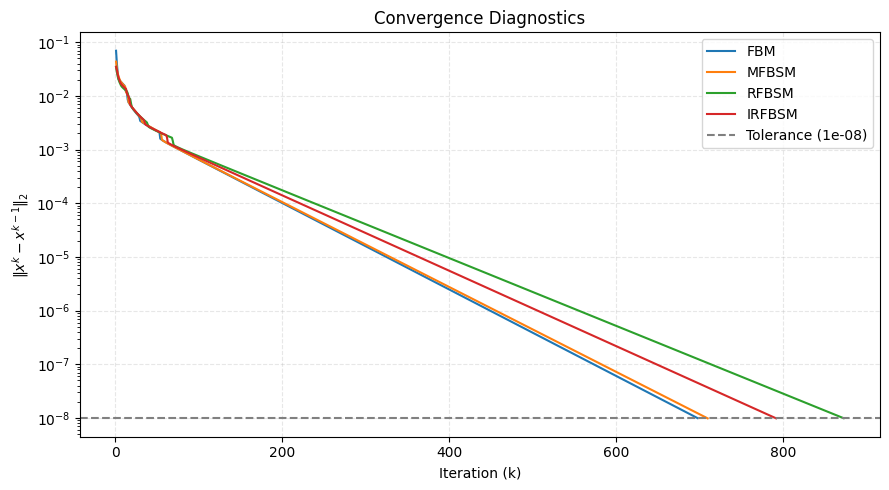

In [10]:
for name, result in results_ff10.items():
    print(f"\n===== {name} - FF10 =====")
    display(show_iteration_table(result))

plot_convergence(results_ff10, tol=tol)

## Chạy thử nghiệm với FF48 với 60 tháng gần nhất

In [11]:
x0, B, prox, gamma, mu, p = prepare_problem(data_ff48)

results_ff48 = {
    "FBM": fbm(x0, B, prox, gamma, max_iter=max_iter, tol=tol),
    "MFBSM": mfbm_tseng(x0, B, prox, gamma, max_iter=max_iter, tol=tol),
    "RFBSM": rmfbsm(x0, B, prox, gamma, theta, mu_step,
                     max_iter=max_iter, tol=tol),
    "IRFBSM": irfbsm(x0, x0, B, prox, gamma, theta, mu_step, alpha,
                      max_iter=max_iter, tol=tol)
}

for name, result in results_ff48.items():
    print(name, "| Số vòng:", result["iterations"],
          "| Residual:", result["residual"],
          "| Hội tụ:", result["converged"])

FBM | Số vòng: 3763 | Residual: 9.984159368445832e-09 | Hội tụ: True
MFBSM | Số vòng: 3771 | Residual: 9.986335451597297e-09 | Hội tụ: True
RFBSM | Số vòng: 4631 | Residual: 9.995184239609344e-09 | Hội tụ: True
IRFBSM | Số vòng: 4203 | Residual: 9.994168342826604e-09 | Hội tụ: True



===== FBM - FF48 =====


,Iteration (k),x^k (vector),Residual ||x^k - x^(k-1)||₂,Final
0,0,"[0.02083333, 0.02083333, 0.02083333, 0.0208333...",—,False
1,1,"[0.0225729 , 0.02741346, 0.02851744, 0.0274664...",3.186e-02,False
2,10,"[ 2.39644087e-02, 5.86710280e-02, 6.17745559...",8.157e-03,False
3,100,"[ 1.56595925e-03, 8.11780127e-02, 1.02974441...",9.956e-04,False
4,1000,"[-1.03256701e-23, 1.79500303e-02, 3.93103712...",6.107e-05,False
5,3763,"[-1.50207530e-23, -1.24003591e-22, 3.08373223...",9.984e-09,True



===== MFBSM - FF48 =====


,Iteration (k),x^k (vector),Residual ||x^k - x^(k-1)||₂,Final
0,0,"[0.02083333, 0.02083333, 0.02083333, 0.0208333...",—,False
1,1,"[0.0233524 , 0.02738638, 0.02847343, 0.0276013...",2.832e-02,False
2,10,"[0.02561678, 0.0579287 , 0.06063327, 0.0620576...",8.149e-03,False
3,100,"[2.11946814e-03, 8.11879690e-02, 1.02682609e-0...",9.977e-04,False
4,1000,"[ 4.84169397e-08, 1.79816851e-02, 3.93531563...",6.111e-05,False
5,3771,"[-2.38139315e-11, 1.07714238e-11, 3.08373305...",9.986e-09,True



===== RFBSM - FF48 =====


,Iteration (k),x^k (vector),Residual ||x^k - x^(k-1)||₂,Gamma,Final
0,0,"[0.02083333, 0.02083333, 0.02083333, 0.0208333...",—,3.192868e+00,False
1,1,"[0.02284858, 0.02607577, 0.02694541, 0.0262477...",2.265e-02,3.192868e+00,False
2,10,"[0.02654153, 0.05377344, 0.05618108, 0.0570374...",8.125e-03,3.192868e+00,False
3,100,"[5.28485772e-03, 8.43408278e-02, 1.01751277e-0...",1.295e-03,3.192868e+00,False
4,1000,"[ 7.42081770e-08, 2.59399395e-02, 4.44652252...",6.737e-05,3.192868e+00,False
5,4631,"[-2.85851207e-11, 1.38008721e-11, 3.08379395...",9.995e-09,3.192868e+00,True



===== IRFBSM - FF48 =====


,Iteration (k),x^k (vector),Residual ||x^k - x^(k-1)||₂,Gamma,Final
0,0,"[0.02083333, 0.02083333, 0.02083333, 0.0208333...",—,3.192868e+00,False
1,1,"[0.02284858, 0.02607577, 0.02694541, 0.0262477...",2.265e-02,3.192868e+00,False
2,10,"[0.02618817, 0.05559233, 0.05803423, 0.0592016...",7.883e-03,3.192868e+00,False
3,100,"[3.88299738e-03, 8.35255849e-02, 1.02493147e-0...",1.222e-03,3.192868e+00,False
4,1000,"[ 5.92683013e-08, 2.21655851e-02, 4.18584496...",6.472e-05,3.192868e+00,False
5,4203,"[-2.62426354e-11, 1.22807771e-11, 3.08376359...",9.994e-09,3.192868e+00,True


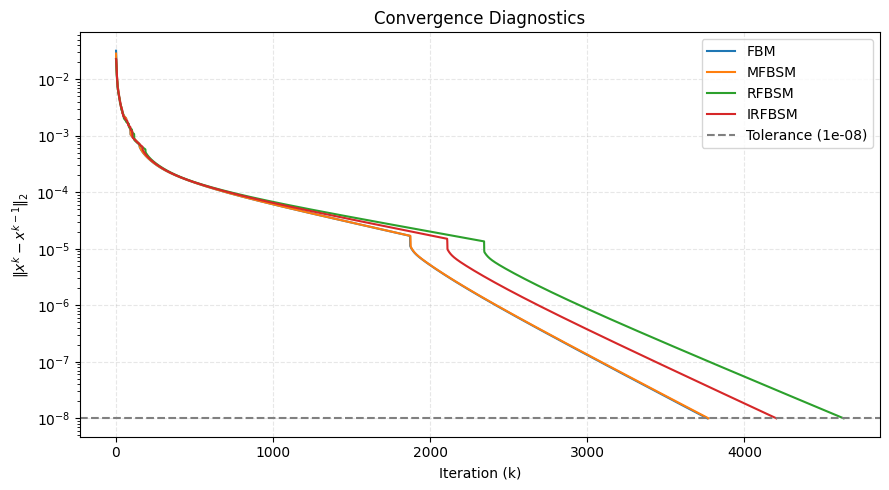

In [12]:
for name, result in results_ff48.items():
    print(f"\n===== {name} - FF48 =====")
    display(show_iteration_table(result))

plot_convergence(results_ff48, tol=tol)

## Chạy thử nghiệm với FF100 với 60 tháng gần nhất

In [13]:
x0, B, prox, gamma, mu, p = prepare_problem(data_ff100)

results_ff100 = {
    "FBM": fbm(x0, B, prox, gamma, max_iter=max_iter, tol=tol),
    "MFBSM": mfbm_tseng(x0, B, prox, gamma, max_iter=max_iter, tol=tol),
    "RFBSM": rmfbsm(x0, B, prox, gamma, theta, mu_step,
                     max_iter=max_iter, tol=tol),
    "IRFBSM": irfbsm(x0, x0, B, prox, gamma, theta, mu_step, alpha,
                      max_iter=max_iter, tol=tol)
}

for name, result in results_ff100.items():
    print(name, "| Số vòng:", result["iterations"],
          "| Residual:", result["residual"],
          "| Hội tụ:", result["converged"])

FBM | Số vòng: 9530 | Residual: 9.997344992349206e-09 | Hội tụ: True
MFBSM | Số vòng: 9539 | Residual: 9.990583014576257e-09 | Hội tụ: True
RFBSM | Số vòng: 11630 | Residual: 9.996352318104325e-09 | Hội tụ: True
IRFBSM | Số vòng: 10592 | Residual: 9.992592681088186e-09 | Hội tụ: True



===== FBM - FF100 =====


,Iteration (k),x^k (vector),Residual ||x^k - x^(k-1)||₂,Final
0,0,"[0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.0...",—,False
1,1,"[0.00915774, 0.00962532, 0.00623222, 0.0097180...",1.366e-02,False
2,10,"[ 3.53625759e-03, 7.91281530e-03, 4.97555584...",6.758e-03,False
3,100,"[ 1.71208259e-02, -7.24481863e-23, -4.38918705...",1.161e-03,False
4,1000,"[ 2.34902480e-02, -8.83638284e-23, -5.15484304...",5.664e-05,False
5,9530,"[1.05209843e-02, 3.60686153e-23, 3.63511811e-2...",9.997e-09,True



===== MFBSM - FF100 =====


,Iteration (k),x^k (vector),Residual ||x^k - x^(k-1)||₂,Final
0,0,"[0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.0...",—,False
1,1,"[0.00948761, 0.00992191, 0.00661543, 0.0100030...",1.312e-02,False
2,10,"[0.00431001, 0.00873722, 0.00068944, 0.0086997...",6.716e-03,False
3,100,"[1.71668716e-02, 1.42704489e-05, 2.03022033e-0...",1.160e-03,False
4,1000,"[2.35178287e-02, 3.18338441e-07, 3.96348577e-0...",5.682e-05,False
5,9539,"[ 1.05209852e-02, 5.04825878e-12, 3.69444063...",9.991e-09,True



===== RFBSM - FF100 =====


,Iteration (k),x^k (vector),Residual ||x^k - x^(k-1)||₂,Gamma,Final
0,0,"[0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.0...",—,1.306306e+00,False
1,1,"[0.00959008, 0.00993753, 0.00729235, 0.0100024...",1.050e-02,1.306306e+00,False
2,10,"[0.00482764, 0.0088328 , 0.00076969, 0.0087118...",6.336e-03,1.306306e+00,False
3,100,"[1.42701499e-02, 2.14527765e-03, 2.52161771e-0...",1.032e-03,1.306306e+00,False
4,1000,"[2.53299592e-02, 6.10064784e-07, 8.13463696e-0...",7.671e-05,1.306306e+00,False
5,10000,"[ 1.05323770e-02, 2.21889478e-11, 1.65251613...",3.446e-08,1.306306e+00,False
6,11630,"[ 1.05218485e-02, 6.32792062e-12, 4.63982737...",9.996e-09,1.306306e+00,True



===== IRFBSM - FF100 =====


,Iteration (k),x^k (vector),Residual ||x^k - x^(k-1)||₂,Gamma,Final
0,0,"[0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.0...",—,1.306306e+00,False
1,1,"[0.00959008, 0.00993753, 0.00729235, 0.0100024...",1.050e-02,1.306306e+00,False
2,10,"[0.00452492, 0.00876572, 0.00074284, 0.0086539...",6.645e-03,1.306306e+00,False
3,100,"[1.56807914e-02, 5.85057475e-04, 2.35061363e-0...",1.121e-03,1.306306e+00,False
4,1000,"[2.49553584e-02, 4.64305254e-07, 6.19447291e-0...",7.085e-05,1.306306e+00,False
5,10000,"[ 1.05239240e-02, 9.41946040e-12, 6.93381905...",1.647e-08,1.306306e+00,False
6,10592,"[ 1.05214164e-02, 5.68684137e-12, 4.16586491...",9.993e-09,1.306306e+00,True


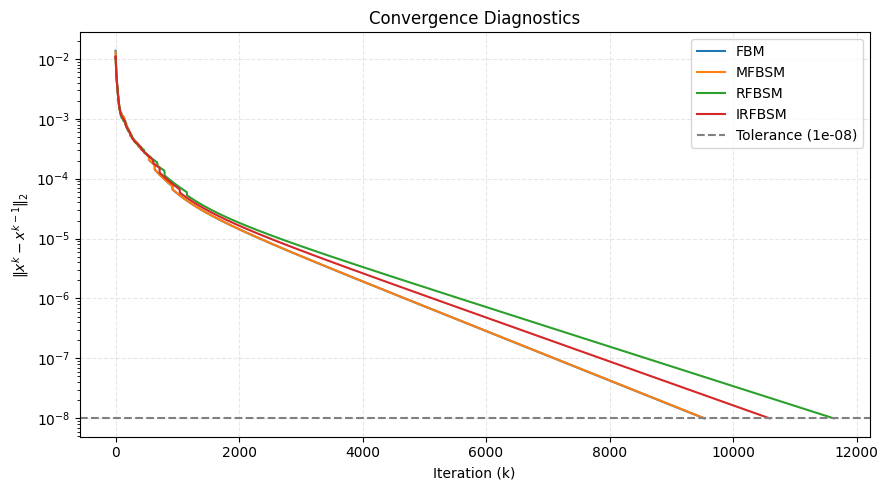

In [14]:
for name, result in results_ff100.items():
    print(f"\n===== {name} - FF100 =====")
    display(show_iteration_table(result))

plot_convergence(results_ff100, tol=tol)